# Layer-wise Incremental Training of Variational Quantum Circuits to Mitigate Barren Plateaus

Interactive walkthrough. This notebook **imports the same tested `src/` modules** used by `run_project.py` -- it does not reimplement the circuit, training loops, or metrics. It (a) demonstrates every pipeline stage live on a small scale, and (b) loads and displays the actual saved results produced by `python run_project.py --mode quick`.

Run `python run_project.py --mode quick` from the project root **before** running this notebook, so that `results/quick/`, `tables/`, and `figures/` are populated.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import load_config, project_path
from src import data_retrieval as dr
from src import preprocessing as pp
from src import circuits as C
from src import training as T
from src import metrics as M
from src import gradient_diagnostics as G

cfg = load_config()
cfg['quick_mode'] = True
cfg

{'project_name': 'vqc_layerwise_credit_risk',
 'quick_mode': True,
 'full_mode': False,
 'label_convention': {'good_credit_uci_class': 1,
  'bad_credit_uci_class': 2,
  'good_credit_encoded_label': -1,
  'bad_credit_encoded_label': 1,
  'positive_class_name': 'bad_credit',
  'decision_threshold': 0.0,
  'note': 'Model output o in [-1,1]. Predicted label = +1 (bad) if o > threshold else -1 (good). Positive class for precision/recall/F1/cost = bad credit (+1).'},
 'cost_matrix': {'source': 'UCI Statlog German Credit documentation, additional_info.summary',
  'note': 'Rows = actual class, columns = predicted class, in original UCI numbering (1=Good, 2=Bad).',
  'cost_actual_good_predicted_bad': 1,
  'cost_actual_bad_predicted_good': 5,
  'cost_actual_good_predicted_good': 0,
  'cost_actual_bad_predicted_bad': 0},
 'data': {'uci_dataset_id': 144,
  'uci_dataset_name': 'Statlog (German Credit Data)',
  'uci_url': 'https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data',
  'uci_d

## 1. Dataset retrieval and validation (real UCI data, cached locally)

In [2]:
df = dr.fetch_raw_dataset(cfg)
print(df.shape)
display(df.head())
y = pp.encode_labels(df, cfg)
print('label counts (good=-1, bad=+1):', np.unique(y, return_counts=True))
meta = dr.load_cached_metadata(cfg)
meta['class_counts'], meta['cost_matrix']

(1000, 21)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


label counts (good=-1, bad=+1): (array([-1,  1]), array([700, 300]))


({'1': 700, '2': 300},
 {'good->bad': 1, 'bad->good': 5, 'good->good': 0, 'bad->bad': 0})

## 2. Leakage-safe preprocessing: split + PCA + angle scaling

In [3]:
data4 = pp.prepare_dataset_for_qubits(df, y, n_qubits=4, cfg=cfg, seed=0)
print('train/val/test:', data4['n_train'], data4['n_val'], data4['n_test'])
print('PCA explained variance ratio (4 components):', data4['pca_explained_variance_ratio'])
print('angle range (train):', data4['X_train_angles'].min(), '-', data4['X_train_angles'].max())
print('angle range (val, clipped to [0,pi]):', data4['X_val_angles'].min(), '-', data4['X_val_angles'].max())

train/val/test: 700 150 150
PCA explained variance ratio (4 components): [0.13166512562213623, 0.11513279372607815, 0.0852192317300775, 0.08170944700533937]
angle range (train): 0.0 - 3.14159265358979
angle range (val, clipped to [0,pi]): 0.0 - 3.129289276425876


## 3. The VQC circuit (actual executed implementation)

Entangling edges, 4 qubits: [(0, 1), (1, 2), (2, 3), (3, 0)]
Entangling edges, 2 qubits (no duplicate): [(0, 1)]
Trainable params, 4 qubits x 6 layers: 48


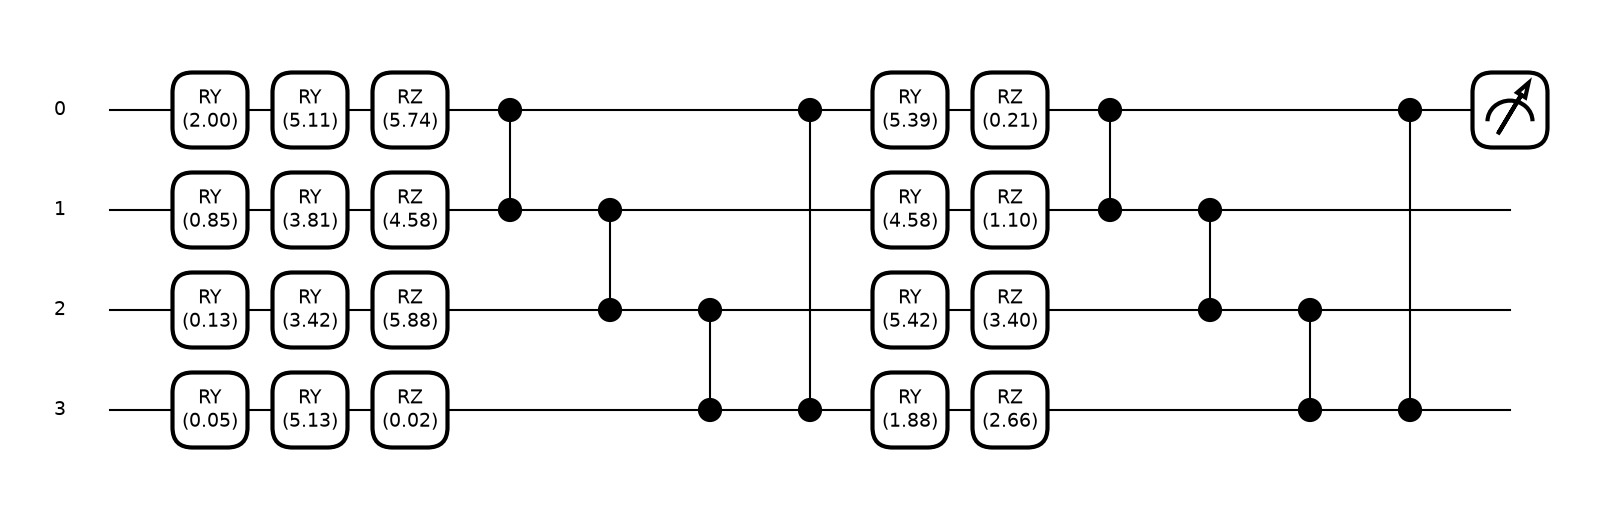

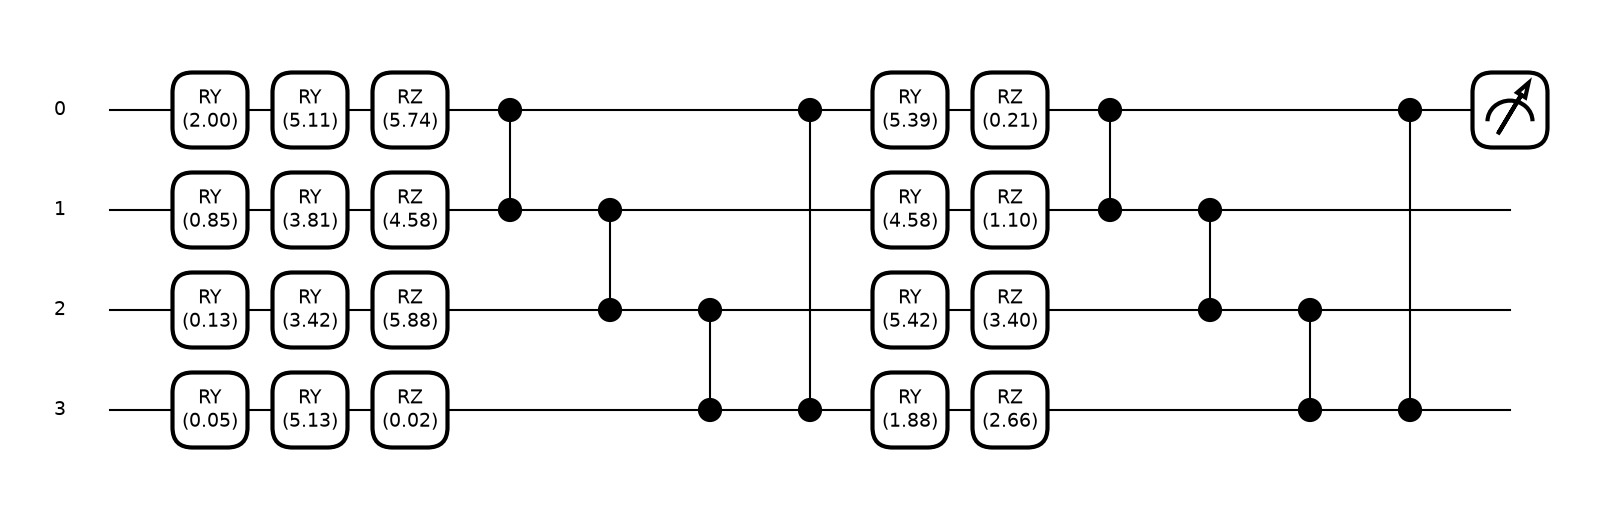

In [4]:
print('Entangling edges, 4 qubits:', C.entangling_edges(4))
print('Entangling edges, 2 qubits (no duplicate):', C.entangling_edges(2))
print('Trainable params, 4 qubits x 6 layers:', C.n_trainable_params(4, 6))
fig, ax = C.circuit_drawing_mpl(4, 2)
fig

## 4. Live mini-demo: Direct vs. Layer-wise Training (small scale, runs in seconds)

This is a live, interactive demonstration at a reduced budget for speed. The authoritative quick-mode results used in the report come from the saved CSVs loaded in Section 5, not from this cell.

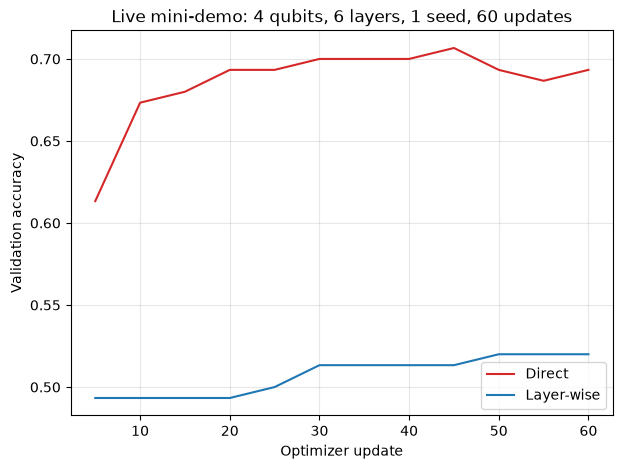

Layer-wise stage logs (loss before/after each layer insertion):
{'layer_idx': 0, 'updates_in_stage': 10, 'loss_prior_stage_end': None, 'loss_immediately_after_insertion': None, 'loss_after_stage': 1.2129431277477125, 'frozen_params_unchanged': True}
{'layer_idx': 1, 'updates_in_stage': 10, 'loss_prior_stage_end': 1.2129431277477125, 'loss_immediately_after_insertion': 1.2129106292446175, 'loss_after_stage': 1.2118224623549059, 'frozen_params_unchanged': True}
{'layer_idx': 2, 'updates_in_stage': 10, 'loss_prior_stage_end': 1.2118224623549059, 'loss_immediately_after_insertion': 1.2124353107521417, 'loss_after_stage': 1.2046638171383381, 'frozen_params_unchanged': True}
{'layer_idx': 3, 'updates_in_stage': 10, 'loss_prior_stage_end': 1.2046638171383381, 'loss_immediately_after_insertion': 1.2046375949568444, 'loss_after_stage': 1.2015493010865748, 'frozen_params_unchanged': True}
{'layer_idx': 4, 'updates_in_stage': 10, 'loss_prior_stage_end': 1.2015493010865748, 'loss_immediately_after

In [5]:
demo_updates = 60
res_direct = T.direct_training_run(4, 6, data4, cfg, seed=0, n_updates=demo_updates, record_grad_every=5)
res_lw = T.layerwise_training_run(4, 6, data4, cfg, seed=0, n_updates_total=demo_updates, record_grad_every=5)

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(res_direct['history']['update'], res_direct['history']['val_accuracy'], label='Direct', color='#d62728')
ax.plot(res_lw['history']['update'], res_lw['history']['val_accuracy'], label='Layer-wise', color='#1f77b4')
ax.set_xlabel('Optimizer update'); ax.set_ylabel('Validation accuracy')
ax.set_title('Live mini-demo: 4 qubits, 6 layers, 1 seed, 60 updates')
ax.legend(); ax.grid(alpha=0.3)
plt.show()

print('Layer-wise stage logs (loss before/after each layer insertion):')
for s in res_lw['stage_logs']:
    print(s)

m_direct = T.evaluate_on_split(res_direct, data4['X_test_angles'], data4['y_test'], cfg)
m_lw = T.evaluate_on_split(res_lw, data4['X_test_angles'], data4['y_test'], cfg)
print('Direct test balanced accuracy:', m_direct['balanced_accuracy'])
print('Layer-wise test balanced accuracy:', m_lw['balanced_accuracy'])

## 5. Saved quick-mode results: main grid

In [6]:
main_df = pd.read_csv(project_path('results', 'quick', 'main_grid_results.csv'))
display(main_df[['run_id','protocol','n_qubits','n_layers','seed','status','test_balanced_accuracy','test_f1','total_wall_clock_s']])

,run_id,protocol,n_qubits,n_layers,seed,status,test_balanced_accuracy,test_f1,total_wall_clock_s
0,main_nq4_d2_direct_seed0_shotsNone_noise0.0,direct,4,2,0,success,0.522222,0.085106,3.023185
1,main_nq4_d2_direct_seed1_shotsNone_noise0.0,direct,4,2,1,success,0.447619,0.157895,2.930034
2,main_nq4_d2_direct_seed2_shotsNone_noise0.0,direct,4,2,2,success,0.517460,0.083333,2.936282
3,main_nq4_d2_layerwise_seed0_shotsNone_noise0.0,layerwise,4,2,0,success,0.647619,0.486486,2.044892
4,main_nq4_d2_layerwise_seed1_shotsNone_noise0.0,layerwise,4,2,1,success,0.615873,0.406250,2.126668
5,main_nq4_d2_layerwise_seed2_shotsNone_noise0.0,layerwise,4,2,2,success,0.500000,0.000000,2.077341
6,main_nq4_d6_direct_seed0_shotsNone_noise0.0,direct,4,6,0,success,0.573016,0.264151,6.518156
7,main_nq4_d6_direct_seed1_shotsNone_noise0.0,direct,4,6,1,success,0.557143,0.226415,6.536416
8,main_nq4_d6_direct_seed2_shotsNone_noise0.0,direct,4,6,2,success,0.552381,0.222222,6.429666
9,main_nq4_d6_layerwise_seed0_shotsNone_noise0.0,layerwise,4,6,0,success,0.622222,0.479167,3.354363


## 6. Barren-plateau gradient-variance diagnostic (circuit-only, not dataset-dependent)

,n_qubits,n_layers,n_samples,gradient_component_variance,gradient_component_variance_ci_lo,gradient_component_variance_ci_hi,gradient_component_mean,grad_norm_mean,grad_norm_std,init_distribution,gradient_method,fixed_input
0,4,1,60,0.518611,0.403997,0.610843,-0.060700,0.649419,0.317097,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
1,4,2,60,0.235149,0.174230,0.292080,-0.102628,0.798497,0.178776,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
2,4,4,60,0.123459,0.077920,0.168315,-0.023343,0.903627,0.185512,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
3,4,8,60,0.049745,0.032869,0.067263,0.018169,1.196264,0.195946,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
4,4,12,60,0.038069,0.028190,0.047620,0.021736,1.549833,0.195603,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
5,4,16,60,0.031788,0.022746,0.040998,-0.013226,1.843973,0.200444,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
6,4,20,60,0.034045,0.023037,0.044862,0.020179,2.147617,0.211041,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
7,4,24,60,0.032153,0.023554,0.040112,-0.023431,2.328414,0.220175,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
8,6,1,60,0.497924,0.405746,0.571676,-0.007819,0.651310,0.271624,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."
9,6,2,60,0.205431,0.140533,0.263829,0.067969,0.741419,0.237247,"uniform[0, 2*pi)","backprop (exact, autograd)","x_i = pi/4 for all qubits (fixed encoding, var..."


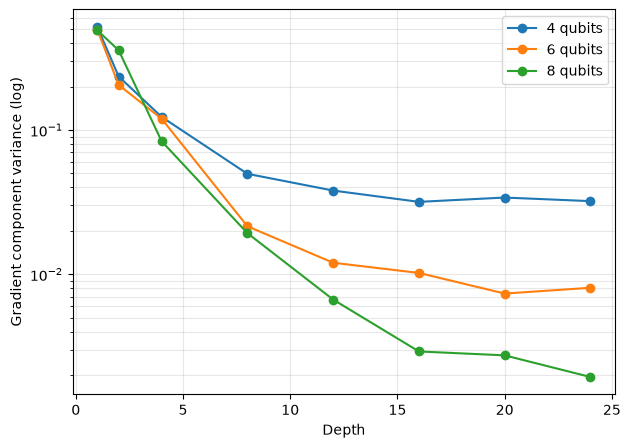

In [7]:
gd_df = pd.read_csv(project_path('tables', 'gradient_diagnostic_summary.csv'))
display(gd_df)
fig2, ax2 = plt.subplots(figsize=(7,5))
for nq in sorted(gd_df.n_qubits.unique()):
    sub = gd_df[gd_df.n_qubits == nq].sort_values('n_layers')
    ax2.plot(sub.n_layers, sub.gradient_component_variance, marker='o', label=f'{nq} qubits')
ax2.set_yscale('log'); ax2.set_xlabel('Depth'); ax2.set_ylabel('Gradient component variance (log)')
ax2.legend(); ax2.grid(alpha=0.3, which='both')
plt.show()

## 7. Tables and figures

All mandatory tables are saved under `tables/*.csv` and `tables/results_summary.xlsx`; all figures (including circuit diagrams for every configuration) are under `figures/`. See `reports/final_report.md` for the full write-up with embedded figures and the honest, evidence-based discussion of which protocol performed better (or didn't) under which conditions.